## Imports
Make sure you install "numpy<2.4" "pandas<3", for compatibility with upsetplot. For opening the excel files, you also need openpyxl and xlrd.

In [1]:
# For hiding pandas future warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# Imports
import re
import sqlite3, openpyxl, xlrd
import pandas as pd
import matplotlib.pyplot as plt

from upsetplot import from_contents, UpSet
%matplotlib inline

## [CompTox-PK-CvT database](https://github.com/USEPA/CompTox-PK-CvTdb)
AUC, CLtot, Vdist, halflife, Css, Cpeak.oral.1mgkg, tpeak.oral, kgutabs

In [2]:
# Connect to database and show all available tables.
con = sqlite3.connect("datasets/CompTox-PK-CvTdb-master/cvt_db_20210607.sqlite")
cursor = con.cursor()
cursor.execute("""SELECT name FROM sqlite_master WHERE type='table';""")
tables = [table[0] for table in cursor.fetchall()]
print(tables)

['studies', 'series', 'chemicals', 'tk_parameters', 'subjects', 'documents', 'conc_time_values']


In [3]:
# Load tk parameters and chemicals into dataframes
cursor.execute("SELECT * FROM tk_parameters")
tk_column_names = [description[0] for description in cursor.description]
tk_parameters = cursor.fetchall()
tk_df = pd.DataFrame(tk_parameters, columns=tk_column_names)

cursor.execute("SELECT * FROM chemicals")
chemical_column_names = [description[0] for description in cursor.description]
chemicals = cursor.fetchall()
chemical_df = pd.DataFrame(chemicals, columns=chemical_column_names)
chemical_df

,id,dsstox_substance_id,dsstox_casrn,preferred_name,chemistry_team_mapping
0,1,DTXSID3061635,1229-55-6,,1
1,2,DTXSID6044519,116-66-5,,1
2,3,DTXSID7031290,54464-57-2,,1
3,4,DTXSID7020687,608-73-1,,1
4,5,DTXSID1021116,62-44-2,,1
...,...,...,...,...,...
175,292,DTXSID10169854,174592-47-3,,1
176,294,DTXSID3037094,68392-35-8,,1
177,295,DTXSID20230862,81024-43-3,,1
178,296,DTXSID6022896,50-47-5,,1


In [4]:
tk_df.parameter_name.value_counts()

parameter_name
AUC                                    756
CLtot                                  158
Vdist                                  158
halflife                               158
Css                                    158
                                      ... 
AUC 0-12 h                               1
Ae 0-24 h                                1
GI 24 h                                  1
plasma protein binding (1.25 ug/mL)      1
initial half-life                        1
Name: count, Length: 64, dtype: int64

In [5]:
# The CAS # for Ma Huang (https://comptox.epa.gov/dashboard/chemical/details/DTXSID80904678) is 85940-38-1, not NOCAS_904678.
chemical_df['dsstox_casrn'] = chemical_df['dsstox_casrn'].replace({'NOCAS_904678': '85940-38-1'})
# Save CAS ids to csv file.
chemical_df.dsstox_casrn.drop_duplicates().to_csv('csv_files/comptox.csv', index=False)

## [Lombardo *et al.*](https://dmd.aspetjournals.org/content/suppl/2018/08/16/dmd.118.082966.DC1)
VDss, CL, fu, MRT, t1/2

In [6]:
lombardo_df = pd.read_excel('Lombardo-1352/Supplemental_82966_revised_corrected.xlsx', header=8)
lombardo_df

,Name,CAS #,SMILES,human VDss (L/kg),human CL (mL/min/kg),fraction unbound \nin plasma (fu),MRT (h),terminal t1/2 (h),Reference,Comments,Notes,Year of first disclosure,MW,HBA,HBD,TPSA_NO,RotBondCount,moka_ionState7.4,MoKa.LogP,MoKa.LogD7.4
0,α-hANP,85637-73-6,N1[C@H](C(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@H](C(...,0.20,25.40,NaN,0.13,0.22,"Nakao, K.; Sugawara, A.; Morii, N.; Sakamoto, ...",α-Human Atrial Natriuretic Peptide. MRT calcul...,NaN,1982,3080.44,84,53,1403.4,75,cationic,-9.00,-9.000
1,(-)dOTC,160707-69-7,c1cn(c(=O)nc1N)[C@H]2CO[C@H](S2)CO,1.18,3.00,NaN,6.50,19.20,"PATRICK F. SMITH, ALAN FORREST, CHARLES H. BAL...",Dosed as 100 mg of racemate. (-) form called a...,NaN,1994,229.26,6,2,90.4,2,neutral,-1.90,-1.900
2,(+)dOTC,160707-68-6,c1cn(c(=O)nc1N)[C@@H]2CO[C@@H](S2)CO,0.84,3.90,NaN,3.60,8.92,"PATRICK F. SMITH, ALAN FORREST, CHARLES H. BAL...",Dosed as 100 mg of racemate. (-) form called a...,NaN,1994,229.26,6,2,90.4,2,neutral,-1.90,-1.900
3,"1,3-DCQA",19870-46-3,O[C@@H]1C[C@@](C[C@@H](OC(=O)\C=C\c2ccc(O)c(O)...,0.79,8.70,NaN,1.50,1.37,"Wen-Zheng Ju,Yang Zhao,Fang Liu,Ting Wua,Jun Z...","1,3-dicaffeoylquinic acid. Data digitized from...",NaN,1964,516.45,12,7,211.3,9,anionic,2.10,-1.600
4,16-acetyl gitoxin,7242-07-1,C1([C@@H]2[C@@]3([C@@]([C@@H]4[C@@H]([C@@]5(CC...,0.78,0.18,0.07,72.30,51.60,"Hausten, K.-O. On the Pharmacokinetics of 16-A...","16-O-acetylgitoxin. N=6, 65.3 kg average weigh...",NaN,1960,822.98,15,5,209.1,9,neutral,0.93,0.930
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1347,Zonampanel,210245-80-0,OC(=O)CN1C(=O)C(=O)Nc2cc(c(cc12)n3ccnc3)N(=O)=O,0.19,5.30,NaN,0.60,0.78,"Minematsu T, Sohida KY, Hashimoto T, Imai H, U...",NaN,NaN,1998,331.24,11,2,150.4,4,anionic,-0.45,-3.800
1348,Zoniporide,241800-98-6,C(=O)(NC(=N)N)c1c(n(nc1)c1c2c(ccc1)nccc2)C1CC1,1.70,21.00,0.34,1.30,2.00,Cross-Species Comparison of the Metabolism and...,"MRT from clearance and VDss. 80 mg, 1 h infusion.",NaN,1999,320.35,7,3,109.7,4,neutral,1.00,1.000
1349,Zopiclone,43200-80-2,CN1CCN(CC1)C(=O)OC2N(C(=O)c3nccnc23)c4ccc(Cl)cn4,1.30,3.30,0.20,6.60,5.20,"Gaillot J, Heusse D, Hougton GW, Marc Aurele J...",NaN,NaN,1973,388.81,9,0,91.8,3,cationic,0.77,0.045
1350,Zoptarelin doxorubicin,139570-93-7,COc1cccc2C(=O)c3c(O)c4C[C@](O)(C[C@H](O[C@H]5C...,NaN,22.00,NaN,NaN,2.02,"Günter Emons, Manfred Kaufmann, Grigor Gorchev...",AEZS-108. Weighted average based on cycles on ...,NaN,1994,1893.01,45,23,713.4,48,cationic,-1.80,-6.300


In [7]:
# Save CAS ids to csv file.
lombardo_df['CAS #'].drop_duplicates().to_csv('csv_files/lombardo.csv', index=False)

## [Obach *et al.*](https://dmd.aspetjournals.org/content/36/7/1385/tab-figures-data)
VDss, CL, fu, MRT, t1/2

In [8]:
obach_df = pd.read_excel('Obach-670/DMD20479_Trend_analysis.xls', header=1)
obach_df

,#,Name,CAS #,VDss (L/kg),CL (mL/min/kg),fu,MRT (h),t1/2 (h),Reference,Comments
0,1,Abacavir,136470-78-5,0.84,13.00,0.5,1.1,1.00,"Chittick GE, Gillotin C, McDowell JA, Lou Y, E...",NaN
1,2,Abanoquil,90402-40-7,6.30,14.00,NF,7.6,5.90,"Schafers RF, Elliott HL, Meredith PA, Miller S...",NaN
2,3,Acarbose,56180-94-0,0.32,2.20,NF,2.4,2.70,"Putter J, Keup U, Krause HP, Muller L, and Web...",NaN
3,4,Acebutolol,37517-30-9,1.70,10.00,0.74,2.8,3.50,"Kaye CM, Kumana CR, Leighton M, Hamer J, and T...","Vss calculated from digitized plots from Kaye,..."
4,5,Acecainide (N-acetylprocainamide),32795-44-1,1.90,4.00,0.9,7.9,6.40,"Coyle JD, Boudoulas H, and Lima JJ (1991) Acec...",NaN
...,...,...,...,...,...,...,...,...,...,...
665,666,Zolmitriptan,139264-17-8,1.80,6.70,0.75,4.6,3.60,"Seaber EJ, Peck RW, Smith DA, Allanson J, Heft...",NaN
666,667,Zolpidem,82626-48-0,0.54,4.30,0.08,2.1,1.70,"Thenot JP, Hermann P, Durand A, Burke JT, Alle...",NaN
667,668,Zonampanel,210245-80-0,0.19,5.30,NF,0.6,0.78,"Minematsu T, Sohida KY, Hashimoto T, Imai H, U...",NaN
668,669,Zopiclone,43200-80-2,1.30,3.30,0.2,6.6,5.20,"Gaillot J, Heusse D, Hougton GW, Marc Aurele J...",NaN


In [9]:
# Save CAS ids to csv file.
obach_df['CAS #'].drop_duplicates().to_csv('csv_files/obach.csv', index=False)

## [e-Drug3D](https://chemoinfo.ipmc.cnrs.fr/MOLDB/index.php)
VD, CL, t1/2, PPB, F, Cmax, Tmax, solublility

In [10]:
edrug_df = pd.read_csv('datasets/eDrug-2083/e-Drug3D_2083_PK.txt', sep=';')
# Remove whitespaces from column names and CAS ids.
edrug_df.rename(columns=lambda x: x.strip(), inplace=True)
edrug_df['CAS'] = [s.strip() for s in edrug_df.CAS]
edrug_df

,#ID,Name,CAS,Year,Status,Is_a_Metabolite,Has_a_Metabolite,Route,VD(liter),Cl(liter/hour),t1/2(hour),PPB(percentage),F(percentage),Cmax,Cmax_unit,Tmax(hour),Solubility
0,1,SULFAPYRIDINE,144-83-2,1939,DISCONTINUED,81,,ORAL,,,,,,,,,
1,2,TRIPTORELIN,57773-63-4,2000,,,,INTRAMUSCULAR,31.5,12.7,3,,,33.6,NANOMOLAR,,
2,3,HISTAMINE,51-45-6,1939,DISCONTINUED,,,INJECTION,59,210,0.18,,,38,NANOMOLAR,0.3,
3,4,BUTABARBITAL,125-40-6,1939,DISCONTINUED,,,ORAL,,,100,,,,,,SOLUBILITY FREELY SOLUBLE IN WATER
4,5,DESOXYCORTICOSTERONE ACETATE,56-47-3,1939,DISCONTINUED,,1791,INJECTION IMPLANTATION,,,,,,,,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2078,2079,NIRMATRELVIR,2628280-40-8,2023,,,,ORAL,104.7,8.99,6.05,69,,6.8,MICROMOLAR,3,
2079,2080,REZAFUNGIN,1396640-59-7,2023,,,,INTRAVENOUS,67,0.35,152,97.1,,15.6,MICROMOLAR,,SOLUBILITY FREELY SOLUBLE IN WATER
2080,2081,ELACESTRANT,722533-56-4,2023,,,,ORAL,5800,186,40,99,10,259.5,NANOMOLAR,2.5,SOLUBILITY FREELY SOLUBLE IN 0.01N HCL
2081,2082,LENIOLISIB,1354690-24-6,2023,,,,ORAL,28.5,,10,94.5,,,,1,SOLUBILITY DECREASING SOLUBILITY OBSERVED WIT...


In [11]:
# Save CAS ids to csv file.
edrug_df.CAS.drop_duplicates().to_csv('csv_files/edrug.csv', index=False)

## [Adachi *et al.*](https://www.jstage.jst.go.jp/article/bpb/45/12/45_b22-00502/_article#supplimentary-materials-wrap)
Cmax, AUC for plasma, liver and kidney

In [12]:
adachi_df = pd.read_excel('Adachi-355/BPB human PBPK 355_si_Table S3_outputs.xlsx', header=8)
adachi_df

,Compound,Cas No.,In vivo-derived,In silico-derived,In vivo-derived.1,In silico-derived.1,In vivo-derived.2,In silico-derived.2,In vivo-derived.3,In silico-derived.3,In vivo-derived.4,In silico-derived.4,In vivo-derived.5,In silico-derived.5
0,"1,4-Dibromobenzene",106-37-6,73.9,103.0,1530.0,1590.0,2540.0,3760.0,12100.0,11400.0,484.0,671.0,10000.0,10400.0
1,"1,4-Dioxane",123-91-1,2030.0,807.0,41800.0,8590.0,1400.0,568.0,29400.0,5990.0,1400.0,556.0,29000.0,5910.0
2,2-Aminobiphenyl,90-41-5,30.6,96.7,227.0,653.0,255.0,795.0,962.0,2770.0,129.0,407.0,961.0,2750.0
3,2-Mercaptobenzimidazole,583-39-1,663.0,600.0,9000.0,12200.0,4450.0,2790.0,31300.0,43400.0,2270.0,2050.0,30800.0,41800.0
4,"3,5-Dimethylaniline",108-69-0,20.6,86.4,164.0,986.0,83.6,474.0,249.0,1550.0,31.0,130.0,248.0,1490.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
362,Quazepam,36735-22-5,86.9,271.0,789.0,991.0,709.0,4460.0,5070.0,6290.0,554.0,1730.0,5040.0,6320.0
363,Sulfamethoxazole,723-46-6,3540.0,1580.0,50100.0,5000.0,2600.0,1200.0,36800.0,3670.0,2590.0,1150.0,36700.0,3620.0
364,Trifluoperazine,117-89-5,33.6,78.5,412.0,863.0,933.0,1670.0,3000.0,6130.0,232.0,541.0,2840.0,5950.0
365,Trimethoprim,738-70-5,616.0,82.9,8210.0,1070.0,721.0,256.0,6390.0,859.0,471.0,62.7,6280.0,808.0


In [13]:
# The CAS # for Rifabutin is 72559-06-9, not 25807831.
adachi_df['Cas No.'] = adachi_df['Cas No.'].replace({25807831: '72559-06-9'})

# Save CAS ids to csv file.
adachi_df.dropna(subset=['Cas No.'], inplace=True)
adachi_df['Cas No.'].drop_duplicates().to_csv('csv_files/adachi.csv', index=False)

## [Paixão *et al.*](https://www.sciencedirect.com/science/article/pii/S0378517312002414)

Foral, frenal, fp, CLplasma, Rb, CLH Fabs, Fmet

Note: the csv was generated from the paper pdf using the scripts in Paixao-164/helper-scripts

In [14]:
paixao_df = pd.read_csv('datasets/Paixao-164/table2_with_cas.csv')
paixao_df

,drug,Foral,frenal,fp,Clplasma_ml_min_kg,Rb,drug_class,ClH_ml_min_kg,Fabs,Fmet,refs,name_used,cid,cas,cas_all,cas_source
0,Acebutolol,0.37,0.40,0.26,6.8,1.00,B,4.1,0.46,0.80,A,Acebutolol,1978,37517-30-9,37517-30-9;28197-63-9,pubchem
1,Acetaminophen,0.88,0.30,0.20,5.0,1.04,B,2.4,1.00,0.88,B,Acetaminophen,1983,103-90-2,103-90-2,pubchem
2,Acyclovir,0.30,0.75,0.15,6.2,1.08,N,1.4,0.32,0.93,B,Acyclovir,135398513,59277-89-3,59277-89-3,pubchem
3,Alendronate,0.02,0.45,0.78,1.1,1.70,Z,0.4,0.02,0.98,B,Alendronate,2088,66376-36-1,66376-36-1,pubchem
4,Allopurinol,0.90,0.12,0.01,9.9,1.09,N,1.9,1.00,0.90,B C,Allopurinol,135401907,315-30-0,315-30-0;180749-06-8;180749-08-0;73334-58-4;18...,pubchem
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
159,Warfarin,0.93,0.02,0.99,0.1,0.55,A,0.1,0.93,1.00,B,Warfarin,54678486,81-81-2,81-81-2;951658-59-6,pubchem
160,Zaleplon,0.31,0.01,0.60,15.7,0.99,N,13.8,1.00,0.31,B,Zaleplon,5719,151319-34-5,151319-34-5;1007130-22-4,pubchem
161,Zidovudine,0.63,0.18,0.25,26.0,1.06,N,7.4,1.00,0.63,B,Zidovudine,35370,30516-87-1,30516-87-1;399024-19-2,pubchem
162,Ziprasidone,0.59,0.01,1.00,11.7,0.81,B,8.2,1.00,0.59,B,Ziprasidone,60854,146939-27-7,146939-27-7,pubchem


In [15]:
# Some names resolve to multiple CAS numbers, find out which of the aliases are found in the other databases, and assume they overlap (as CAS number differences often are free base vs salt form etc.).
other_datasets = {
    'CompTox': load_cas_file('csv_files/comptox.csv'),
    'Lombardo $et$ $al.$': load_cas_file('csv_files/lombardo.csv'),
    'Adachi $et$ $al.$': load_cas_file('csv_files/adachi.csv'),
    'e-Drug3D': load_cas_file('csv_files/edrug.csv'),
}
paixao_primary_cas = set(paixao_df.cas)
others = {k: set(v) for k, v in other_datasets.items()}

rows = []
for _, r in paixao_df.iterrows():
    # Split the ; separated cas_all string, then clean up and drop the primary cas # and any cas # that is found in other databases.
    aliases = [a.strip() for a in str(r.cas_all).split(';')
               if a.strip() and a.strip() != r.cas and a.strip() not in paixao_primary_cas]
    for db, s in others.items():
        hits = [a for a in aliases if a in s]
        # Add records for when a primary cas # is not in the other databases, but one of the aliases is.
        if hits and r.cas not in s:
            rows.append((r.drug, db, r.cas, hits))

alias_hits = pd.DataFrame(rows, columns=['drug', 'database', 'primary_cas', 'matched_alias'])
alias_hits

,drug,database,primary_cas,matched_alias
0,Doxycycline,Lombardo $et$ $al.$,7164-70-7,[564-25-0]
1,Doxycycline,e-Drug3D,7164-70-7,[564-25-0]
2,Ibuprofen,CompTox,58560-75-1,[15687-27-1]
3,Ibuprofen,Lombardo $et$ $al.$,58560-75-1,[15687-27-1]
4,Ibuprofen,Adachi $et$ $al.$,58560-75-1,[15687-27-1]
5,Ibuprofen,e-Drug3D,58560-75-1,[15687-27-1]
6,Metoprolol,e-Drug3D,51384-51-1,[37350-58-6]


In [16]:
# As seen above, some cas numbers indeed are different, but before changing them, we'll need to see if the current primary cas # maybe also has a hit.
check = []
for drug, group in alias_hits.groupby('drug'):
    old_cas = group.primary_cas.iloc[0]
    new_cas = sorted({a for hits in group.matched_alias for a in hits})
    old_found_in = [db for db, s in others.items() if old_cas in s]
    check.append({
        'drug': drug,
        'old_cas': old_cas,
        'new_cas': new_cas,
        'old_cas_found_in': old_found_in,
    })

swap_check = pd.DataFrame(check)
swap_check

,drug,old_cas,new_cas,old_cas_found_in
0,Doxycycline,7164-70-7,[564-25-0],[]
1,Ibuprofen,58560-75-1,[15687-27-1],[]
2,Metoprolol,51384-51-1,[37350-58-6],"[CompTox, Lombardo $et$ $al.$, Adachi $et$ $al.$]"


In [17]:
# For the Doxycycline and Ibuprofen cas # it is safe to change to a new primary in the paixao set.
paixao_df['cas'] = paixao_df.drug.map({'Doxycycline': '564-25-0', 'Ibuprofen': '15687-27-1'}).fillna(paixao_df.cas)

# As the cas change in Metroprolol would lose the overlap with some databases, in this case it is better to change it in the one database that is different: e-Drug3D, as 51384-51-1 and 37350-58-6 both refer to Metroprolol.
edrug_df['CAS'] = edrug_df.CAS.map({'37350-58-6': '51384-51-1'}).fillna(edrug_df.CAS)

In [18]:
# Save CAS ids to csv files.
paixao_df.cas.drop_duplicates().to_csv('csv_files/paixao.csv', index=False)
edrug_df.CAS.drop_duplicates().to_csv('csv_files/edrug.csv', index=False)

## Plotting

In [36]:
cas_pattern = r"\d{2,7}-\d{2}-\d"
def load_cas_file(path):
    """Load and check the CAS numbers in the csv file."""
    series = pd.read_csv(path, dtype="string").iloc[:, 0].str.replace(r"\s+", "", regex=True)
    is_cas = series.str.fullmatch(cas_pattern)
    invalid = series[~is_cas].unique()
    if len(invalid):
        print(f"{path}: not matching CAS format: {list(invalid)}")
    return pd.Index(series[is_cas].unique())

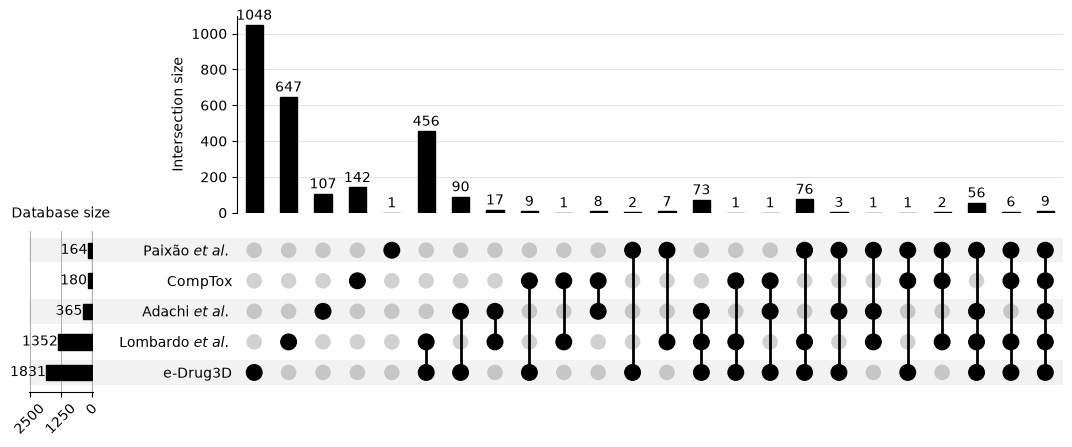

In [39]:
databases = {
    'Paixão $et$ $al.$': load_cas_file('csv_files/paixao.csv'),
    'CompTox': load_cas_file('csv_files/comptox.csv'),
    'Lombardo $et$ $al.$': load_cas_file('csv_files/lombardo.csv'),
    'Adachi $et$ $al.$': load_cas_file('csv_files/adachi.csv'),
    'e-Drug3D': load_cas_file('csv_files/edrug.csv'),
    # Obach et al. is left out, as Lombardo et al. is the updated version of this database.
}

overlap_df = from_contents(databases)

# Plot UpSet plot
ax_dict = UpSet(overlap_df, subset_size='count',
                # For setting minimum intersection size (optional).
                # min_subset_size=3,
                show_counts=True).plot()

ax_dict['totals'].set_xlabel('Database size')
ax_dict['totals'].xaxis.set_label_coords(0.5, 1.15)
ax_dict['totals'].grid(False)
ax_dict['totals'].axvline(0, linewidth=1, color='#B0B0B0', zorder=0)
x_ticks = [0,1250,2500]
for x_tick in x_ticks:
    ax_dict['totals'].axvline(x_tick, linewidth=0.75, color='#B0B0B0', zorder=0)
ax_dict['totals'].set_xlim([2525,-25])
ax_dict['totals'].set_xticks(x_ticks)
ax_dict['totals'].tick_params(axis='x', rotation=45)

plt.savefig('plots/Database_overlap.png', dpi=400, bbox_inches='tight')
plt.savefig('plots/Database_overlap.pdf', bbox_inches='tight')